# Estágio 01 — Merge dos dados dos caudalímetros

Junta todos os exports NIVUS de cada estação num único dataset contínuo, que é o ponto de entrada dos estágios seguintes.

**Entrada:** `RAW_DIR/<Estação>/<período>/**/DATA/*.CSV` (uma pasta por descarga do equipamento)

**Saída** (em `data/interim/`):

| Ficheiro | Para quê |
|---|---|
| `<estação>_merged.csv` | tabela canónica (`datetime` + colunas numéricas) usada pelos próximos estágios |
| `<estação>_merged_nivus.CSV` | o mesmo conteúdo no formato do equipamento, para ferramentas que esperam um export NIVUS (ex.: calibração no webapp) |
| `<estação>_merge_report.json` | proveniência: ficheiros lidos, timestamps repetidos e falhas de cobertura |

**Regras deste estágio:**

- ordena cronologicamente e resolve timestamps repetidos entre descargas sobrepostas (ganha o export cuja cobertura começa mais tarde);
- é fiel aos dados: **não** remove outliers, caudais negativos nem alturas fora da faixa operacional — isso é o estágio de limpeza.

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

from pipeline_config import FIGURES_DIR, INTERIM_DIR, RAW_DIR, STATIONS

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 30)

for directory in (INTERIM_DIR, FIGURES_DIR):
    directory.mkdir(parents=True, exist_ok=True)

print("dados brutos:", RAW_DIR)
print("saída:       ", INTERIM_DIR)
print("estações:    ", ", ".join(STATIONS))

dados brutos: /Users/marcosgrandesso/Downloads/Dados de Projeto/Caudalímetros
saída:        /Users/marcosgrandesso/wada/afluencia_indevida_pipeline/data/interim
estações:     ameal, antanhol


## 1. Descoberta dos ficheiros

Cada descarga cria uma pasta `<Estação> - <data> a <data>` com as subpastas `DATA` (série temporal), `DIAG`, `TOTAL` e `PARAM`. Só `DATA` interessa aqui.

Duas armadilhas a tratar:

- algumas descargas têm um nível extra com o número de série (`<período>/ANTANHOL-W2DS_2112NFM1828/DATA/...`), por isso a busca é recursiva;
- o sistema de ficheiros do macOS não distingue maiúsculas, logo `*.CSV` e `*.csv` devolvem os mesmos caminhos e têm de ser desduplicados.

In [2]:
def discover_data_files(station_dir: Path) -> list[Path]:
    """Todos os CSV sob pastas `DATA/`, a qualquer profundidade."""
    seen, files = set(), []
    for candidate in sorted(station_dir.rglob("*")):
        if not candidate.is_file():
            continue
        if candidate.parent.name.upper() != "DATA" or candidate.suffix.lower() != ".csv":
            continue
        key = str(candidate).lower()
        if key not in seen:
            seen.add(key)
            files.append(candidate)
    return files


def period_label(path: Path, station_dir: Path) -> str:
    """Nome da pasta de descarga a que o ficheiro pertence."""
    parts = path.relative_to(station_dir).parts
    return parts[0] if len(parts) > 1 else path.name


for slug, station in STATIONS.items():
    found = discover_data_files(RAW_DIR / station["folder"])
    print(f"{slug}: {len(found)} ficheiros DATA")

ameal: 16 ficheiros DATA
antanhol: 16 ficheiros DATA


## 2. Leitura do formato NIVUS

Um export tem metadados do equipamento, a linha de cabeçalho, uma linha vazia e depois os dados:

```
NIVUS;AMEAL
;
;
Date:;06.08.2026
Serial No.:;2112NFM1827;Art.-No.:;NFM-0750G0E0;Version:;V6.0.3 03/12/25;...
;
;
UTC+1 [h]
Date;Time;app1_sum [m³];app1_q [l/s];app1_h [m];app1_v [m/s];...

06.08.2026;09:46:00;5959,741;1,04;0,075;0,102;25,0;12,89;144,426
```

O que o leitor abaixo absorve:

- **o número de linhas de metadados varia entre firmwares** (há ficheiros de 2025 e de 2026 nas mesmas pastas), por isso a linha de cabeçalho é localizada pelo prefixo `Date;Time` em vez de um `skiprows` fixo;
- os ficheiros podem ou não ter BOM UTF-8 e usam CRLF;
- separador `;`, decimal `,`;
- as colunas são identificadas por fragmento (`app1_q`, `app1_h`, ...) porque o sufixo com unidades muda entre versões.

Os valores ficam como **texto** na leitura. Assim o re-export NIVUS no fim não sofre perdas de arredondamento; a conversão para número acontece só em `to_canonical`.

In [3]:
SEP = ";"
ENCODING = "utf-8-sig"
HEADER_PREFIX = "date;time"
DATETIME_FORMAT = "%d.%m.%Y %H:%M:%S"
L_S_TO_M3_H = 3.6

# nome canónico -> fragmento do cabeçalho NIVUS
CANONICAL_COLUMNS = {
    "volume_acumulado_m3": "app1_sum",
    "caudal_l_s": "app1_q",
    "altura_m": "app1_h",
    "velocidade_m_s": "app1_v",
    "temperatura_agua_c": "app1_t_water",
    "tensao_bateria_v": "app1_u_batt",
    "corrente_bateria_ma": "app1_i_batt",
}
REQUIRED_COLUMNS = ("caudal_l_s", "altura_m", "velocidade_m_s")


class NivusFormatError(ValueError):
    """O ficheiro não tem a estrutura esperada de um export NIVUS."""


def read_header(path: Path) -> list[str]:
    """Linhas de metadados até (e incluindo) a linha `Date;Time`."""
    lines = []
    with path.open(encoding=ENCODING, newline="") as handle:
        for line in handle:
            lines.append(line.rstrip("\r\n"))
            if lines[-1].lower().startswith(HEADER_PREFIX):
                return lines
            if len(lines) > 50:
                break
    raise NivusFormatError(f"Cabeçalho 'Date;Time' não encontrado em {path}")


def read_raw(path: Path) -> pd.DataFrame:
    """Lê um export NIVUS mantendo todos os valores como texto."""
    header_lines = read_header(path)
    frame = pd.read_csv(
        path,
        sep=SEP,
        dtype=str,
        skiprows=len(header_lines) - 1,
        encoding=ENCODING,
        skip_blank_lines=True,
        na_filter=False,
    )
    frame.columns = [str(column).strip() for column in frame.columns]

    missing = [column for column in ("Date", "Time") if column not in frame.columns]
    if missing:
        raise NivusFormatError(f"Colunas {missing} ausentes em {path}")

    frame = frame[(frame["Date"] != "") & (frame["Time"] != "")]
    return frame.reset_index(drop=True)


def parse_datetime(frame: pd.DataFrame) -> pd.Series:
    """Combina `Date` e `Time` num timestamp; valores inválidos ficam NaT."""
    return pd.to_datetime(
        frame["Date"].str.strip() + " " + frame["Time"].str.strip(),
        format=DATETIME_FORMAT,
        errors="coerce",
    )


def find_column(columns, fragment: str) -> str:
    for column in columns:
        if fragment in str(column).lower():
            return column
    raise NivusFormatError(f"Nenhuma coluna contém {fragment!r}")


def to_canonical(frame: pd.DataFrame) -> pd.DataFrame:
    """Converte um frame NIVUS cru na tabela canónica do pipeline."""
    canonical = pd.DataFrame({"datetime": parse_datetime(frame)})
    for name, fragment in CANONICAL_COLUMNS.items():
        try:
            source = find_column(frame.columns, fragment)
        except NivusFormatError:
            if name in REQUIRED_COLUMNS:
                raise
            continue
        text = frame[source].str.strip().str.replace(",", ".", regex=False)
        canonical[name] = pd.to_numeric(text, errors="coerce")
    canonical["caudal_m3_h"] = canonical["caudal_l_s"] * L_S_TO_M3_H
    return canonical


def write_raw(frame: pd.DataFrame, path: Path, header_lines) -> None:
    """Escreve no formato NIVUS: BOM UTF-8, CRLF, separador `;`."""
    body = frame.astype(str).agg(SEP.join, axis=1).tolist()
    text = "\r\n".join([*header_lines, "", *body]) + "\r\n"
    path.write_bytes(b"\xef\xbb\xbf" + text.encode("utf-8"))


def rewrite_header_date(header_lines, period: str) -> list[str]:
    """Troca a linha `Date:;<data>` pelo período coberto pelo merge."""
    return [
        f"Date:{SEP}{period}" if line.lower().startswith("date:;") else line
        for line in header_lines
    ]

## 3. Merge

As descargas sobrepõem-se: a mesma data/hora aparece no fim de um export e no início do seguinte, e há casos em que o nome do ficheiro não corresponde ao período da pasta (ex.: `Ameal - 29.04.2026 a 11.05.2026/DATA/AMEAL_STD_2603091812_...`).

Por isso os ficheiros são ordenados pelo **primeiro timestamp que contêm** (não pelo nome) e, em caso de timestamp repetido, fica a linha do export cuja cobertura começa mais tarde — normalmente a descarga mais recente do equipamento. O número de repetidos vai para o relatório.

Como os firmwares podem exportar conjuntos de colunas diferentes, todos os frames são alinhados às colunas do export mais recente antes de concatenar.

In [4]:
# Uma falha de cobertura é reportada quando o intervalo entre amostras
# consecutivas passa este múltiplo do intervalo de amostragem típico.
GAP_TOLERANCE = 1.5
MAX_REPORTED_GAPS = 15


def find_gaps(timestamps: pd.Series, interval: pd.Timedelta) -> list[dict]:
    deltas = timestamps.diff()
    flagged = deltas[deltas > interval * GAP_TOLERANCE]
    gaps = [
        {
            "start": timestamps[index - 1].isoformat(),
            "end": timestamps[index].isoformat(),
            "duration_hours": round(delta.total_seconds() / 3600, 2),
        }
        for index, delta in flagged.items()
    ]
    return sorted(gaps, key=lambda gap: gap["duration_hours"], reverse=True)


def merge_station(slug: str, station: dict, raw_dir: Path = RAW_DIR, out_dir: Path = INTERIM_DIR):
    """Junta os exports de uma estação e grava as três saídas do estágio.

    Devolve `(merged_raw, canonical, report)`.
    """
    station_dir = raw_dir / station["folder"]
    files = discover_data_files(station_dir)
    if not files:
        raise FileNotFoundError(f"Nenhum CSV em pastas DATA/ sob {station_dir}")

    loaded = []
    for path in files:
        frame = read_raw(path)
        timestamps = parse_datetime(frame)
        valid = timestamps.dropna()
        loaded.append(
            {
                "frame": frame.assign(
                    _datetime=timestamps,
                    _period=period_label(path, station_dir),
                ),
                "header": read_header(path),
                "start": valid.min() if not valid.empty else pd.Timestamp.max,
                "source": {
                    "period": period_label(path, station_dir),
                    "file": path.name,
                    "rows": len(frame),
                    "first_timestamp": valid.min().isoformat() if not valid.empty else None,
                    "last_timestamp": valid.max().isoformat() if not valid.empty else None,
                },
            }
        )

    loaded.sort(key=lambda item: item["start"])
    reference_header = loaded[-1]["header"]
    nivus_columns = [cell.strip() for cell in reference_header[-1].split(SEP)]

    merged = pd.concat(
        [
            item["frame"]
            .reindex(columns=[*nivus_columns, "_datetime", "_period"], fill_value="")
            .assign(_order=order)
            for order, item in enumerate(loaded)
        ],
        ignore_index=True,
    )

    report = {
        "station": slug,
        "raw_dir": str(station_dir),
        "rows_read": len(merged),
        "invalid_timestamps": int(merged["_datetime"].isna().sum()),
    }

    merged = merged.dropna(subset=["_datetime"]).sort_values(
        ["_datetime", "_order"], kind="mergesort"
    )
    before_dedupe = len(merged)
    merged = merged.drop_duplicates(subset=["_datetime"], keep="last").reset_index(drop=True)

    timestamps = merged["_datetime"]
    interval = timestamps.diff().median()
    gaps = find_gaps(timestamps, interval) if interval > pd.Timedelta(0) else []

    report.update(
        duplicate_timestamps=before_dedupe - len(merged),
        rows_written=len(merged),
        first_timestamp=timestamps.iloc[0].isoformat(),
        last_timestamp=timestamps.iloc[-1].isoformat(),
        sampling_interval_minutes=round(interval.total_seconds() / 60, 3),
        gap_count=len(gaps),
        missing_days=round(sum(gap["duration_hours"] for gap in gaps) / 24, 2),
        largest_gaps=gaps[:MAX_REPORTED_GAPS],
        sources=[item["source"] for item in loaded],
        outputs={},
    )

    canonical = to_canonical(merged)
    canonical.insert(1, "station", slug)
    canonical["source_period"] = merged["_period"].to_numpy()

    canonical_path = out_dir / f"{slug}_merged.csv"
    canonical.to_csv(canonical_path, index=False)
    report["outputs"]["canonical"] = str(canonical_path)

    nivus_path = out_dir / f"{slug}_merged_nivus.CSV"
    period = f"{timestamps.iloc[0]:%d.%m.%Y} a {timestamps.iloc[-1]:%d.%m.%Y}"
    write_raw(merged[nivus_columns], nivus_path, rewrite_header_date(reference_header, period))
    report["outputs"]["nivus"] = str(nivus_path)

    report_path = out_dir / f"{slug}_merge_report.json"
    report_path.write_text(json.dumps(report, indent=2, ensure_ascii=False), encoding="utf-8")
    report["outputs"]["report"] = str(report_path)

    return merged, canonical, report

## 4. Execução

In [5]:
merged_raw, canonical_data, reports = {}, {}, {}

for slug, station in STATIONS.items():
    merged_raw[slug], canonical_data[slug], reports[slug] = merge_station(slug, station)
    report = reports[slug]
    print(
        f"{slug}: {len(report['sources'])} ficheiros | "
        f"{report['rows_read']} -> {report['rows_written']} linhas "
        f"({report['duplicate_timestamps']} repetidos, {report['invalid_timestamps']} inválidos) | "
        f"{report['first_timestamp'][:10]} a {report['last_timestamp'][:10]} | "
        f"amostragem {report['sampling_interval_minutes']} min | "
        f"{report['gap_count']} falhas ({report['missing_days']} dias)"
    )

ameal: 16 ficheiros | 192320 -> 192308 linhas (12 repetidos, 0 inválidos) | 2025-05-09 a 2026-09-02 | amostragem 2.0 min | 3 falhas (214.04 dias)
antanhol: 16 ficheiros | 193396 -> 193383 linhas (13 repetidos, 0 inválidos) | 2025-05-09 a 2026-09-02 | amostragem 2.0 min | 3 falhas (212.61 dias)


## 5. Conferência

Proveniência por ficheiro, falhas de cobertura e uma vista do caudal ao longo de todo o período — serve para apanhar descargas trocadas de estação ou períodos em que o equipamento esteve parado.

In [6]:
ESTACAO = "ameal"  # estação inspecionada nas células seguintes

pd.DataFrame(reports[ESTACAO]["sources"])

,period,file,rows,first_timestamp,last_timestamp
0,Ameal - 09.05.2025 a 15.05.2025,AMEAL-W2DS_STD_2505091122_2505151426.CSV,4413,2025-05-09T11:22:00,2025-05-15T14:26:00
1,Ameal - 15.05.2025 a 22.05.2025,AMEAL-W2DS_STD_2505151426_2505221019.CSV,4917,2025-05-15T14:26:00,2025-05-22T10:18:00
2,Ameal - 22.05.2025 a 30.05.2025,AMEAL-W2DS_STD_2505221018_2505301448.CSV,5896,2025-05-22T10:18:00,2025-05-30T14:48:00
3,Ameal - 30.05.2025 a 16.06.2025,AMEAL- 30.05.2025 a 16.06.2025.CSV,12107,2025-05-30T14:48:00,2025-06-16T10:20:00
4,Ameal - 16.06.2025 a 03.07.2025,AMEAL-W2DS_STD_2506161020_2507030929.CSV,12215,2025-06-16T10:20:00,2025-07-03T09:28:00
5,Ameal - 17.07.2025 a 13.08.2025,AMEAL-W2DS_STD_2507171434_2508131008.CSV,19308,2025-07-17T14:34:00,2025-08-13T10:08:00
6,Ameal - 13.08.2025 a 10.09.2025,Ameal - 13.08.2025 a 10.09.2025.CSV,20146,2025-08-13T10:08:00,2025-09-10T09:38:00
7,Ameal - 10.09.2025 a 30.09.2025,AMEAL-W2DS_STD_2509100938_2509301454.CSV,14559,2025-09-10T09:38:00,2025-09-30T14:54:00
8,Ameal - 30.09.2025 a 30.10.2025,AMEAL-W2DS_STD_2509301454_2510301047.CSV,21477,2025-09-30T14:54:00,2025-10-30T10:46:00
9,Ameal - 30.10.2025 a 27.11.2025,AMEAL-W2DS_STD_2510301046_2511271036.CSV,20156,2025-10-30T10:46:00,2025-11-27T10:36:00


In [7]:
pd.DataFrame(reports[ESTACAO]["largest_gaps"])

,start,end,duration_hours
0,2025-12-05T15:32:00,2026-04-29T11:52:00,3476.33
1,2026-05-28T10:06:00,2026-07-22T09:34:00,1319.47
2,2025-07-03T09:28:00,2025-07-17T14:34:00,341.10


In [8]:
canonical_data[ESTACAO].describe().T

,count,mean,min,25%,50%,75%,max,std
datetime,192308,2025-11-17 13:40:41.956444,2025-05-09 11:22:00,2025-07-29 10:59:30,2025-10-04 05:33:00,2026-05-03 20:24:30,2026-09-02 14:24:00,NaN
volume_acumulado_m3,192308.0,7461.902859,0.253,3966.171,6173.12,8615.557,32236.946,6137.669456
caudal_l_s,192308.0,1.617826,-13.35,0.0,0.69,1.34,41.91,3.646194
altura_m,192308.0,0.109843,0.032,0.056,0.071,0.086,1.862,0.152357
velocidade_m_s,192308.0,0.114282,-0.646,0.0,0.113,0.143,1.697,0.148176
temperatura_agua_c,192308.0,21.661657,13.1,18.9,22.1,24.5,26.5,3.110256
tensao_bateria_v,192308.0,12.67734,11.75,12.44,12.68,12.92,13.57,0.357904
corrente_bateria_ma,192308.0,98.532289,82.25,88.833,92.333,109.702,169.25,13.60196
caudal_m3_h,192308.0,5.824175,-48.06,0.0,2.484,4.824,150.876,13.126299


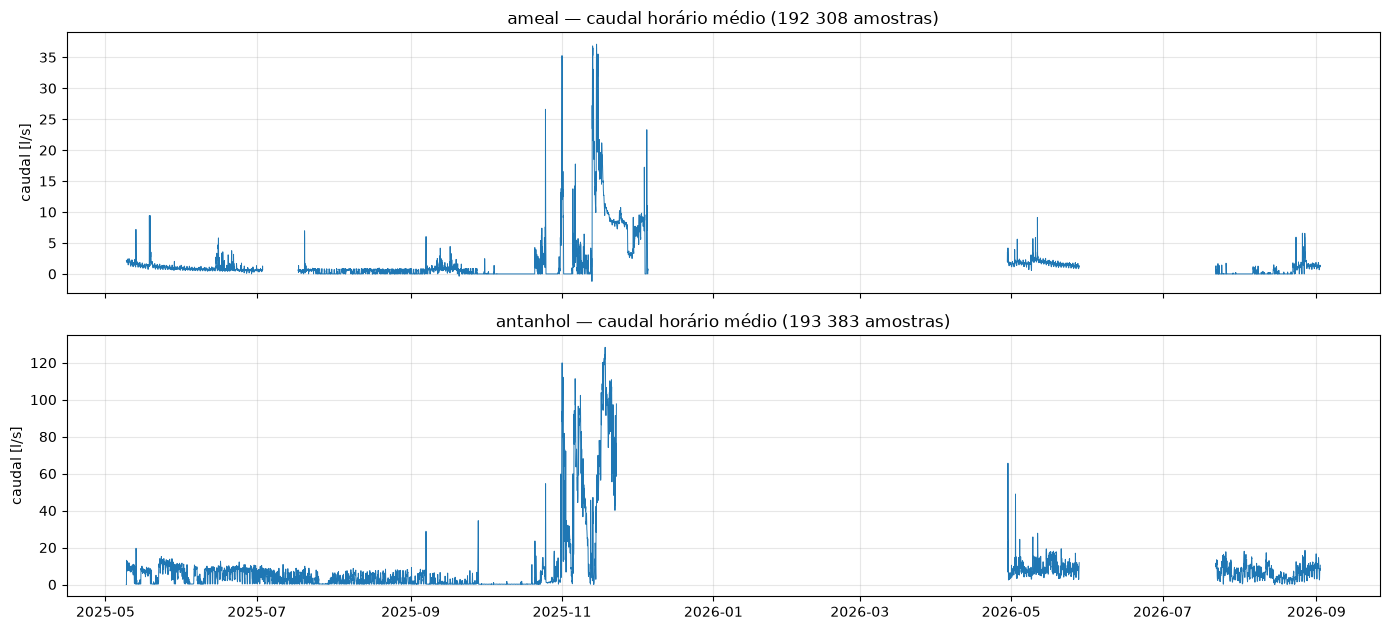

In [9]:
figure, axes = plt.subplots(len(canonical_data), 1, figsize=(14, 3.2 * len(canonical_data)), sharex=True)

for axis, (slug, frame) in zip(axes, canonical_data.items()):
    hourly = frame.set_index("datetime")["caudal_l_s"].resample("1h").mean()
    axis.plot(hourly.index, hourly.to_numpy(), linewidth=0.7)
    axis.set_title(f"{slug} — caudal horário médio ({len(frame):,} amostras)".replace(",", " "))
    axis.set_ylabel("caudal [l/s]")
    axis.grid(alpha=0.3)

figure.tight_layout()
figure.savefig(FIGURES_DIR / "01_merge_caudal.png", dpi=110)
plt.show()

## 6. Verificação do export NIVUS

O ficheiro `*_merged_nivus.CSV` tem de continuar a ser lido pelos parsers que esperam um export do equipamento (`stations/services/flow_rating_csv.py` no backend e `utils/w2ds/flowRatingCsv.js` no webapp). A célula abaixo relê o ficheiro gravado com o mesmo leitor deste notebook e compara com a tabela canónica.

In [10]:
for slug, report in reports.items():
    roundtrip = to_canonical(read_raw(Path(report["outputs"]["nivus"])))
    reference = canonical_data[slug][roundtrip.columns]
    assert roundtrip.equals(reference), f"re-leitura do export NIVUS divergiu em {slug}"
    print(f"{slug}: export NIVUS relido sem divergências ({len(roundtrip)} linhas)")

ameal: export NIVUS relido sem divergências (192308 linhas)
antanhol: export NIVUS relido sem divergências (193383 linhas)


## Próximo estágio

`02` — limpeza: caudais/alturas não positivos, faixa operacional de altura por estação (`collector_diameter_m` em `pipeline_config.py`) e outliers pela razão Q/h.